# Notebook 9 – Data Transformation

# 1. Why Transform Data?


## Step 1 – Understand Concept

Data transformation means changing the numerical representation of a feature so that it becomes more suitable for analysis or Machine Learning.

Raw numerical data may have:

- Strong right or left skewness
- Very large differences between values
- Extreme values
- Non-linear relationships
- Unequal distribution

Transformation can help make the data more balanced and easier for some ML algorithms to work with.

Common transformations include:

- Log Transformation
- Square Root Transformation
- Power Transformation
- Box-Cox Transformation
- Yeo-Johnson Transformation

Transformation does not automatically mean that the data becomes perfectly normal.

The transformation should be selected based on the distribution and characteristics of the feature.



## Step 2 – Demonstrate Concept

Suppose customer spending contains:

10
15
20
25
30
500
1000

Most observations are small, but a few observations are extremely large.

This creates a right-skewed distribution.

A transformation such as log transformation can compress the larger values and make the distribution less skewed.

Before transformation:

Small values are concentrated together and large values are spread far away.

After transformation:

Large values are compressed, making the distribution more balanced.



## Step 3 – Implement the Concept


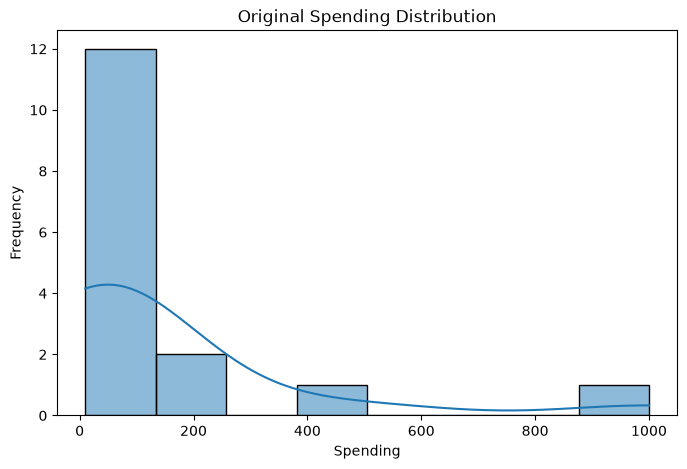

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Spending": [
        10, 12, 15, 18, 20, 25,
        30, 35, 40, 50, 70, 100,
        150, 250, 500, 1000
    ]
})

plt.figure(figsize=(8, 5))
sns.histplot(df["Spending"], kde=True)
plt.title("Original Spending Distribution")
plt.xlabel("Spending")
plt.ylabel("Frequency")
plt.show()

## Result / Observation

The original feature has a strong right-skewed distribution.

Most observations are concentrated at lower values, while a few large observations extend the distribution toward the right.

A suitable transformation can be investigated to reduce this skewness.

# 2. Log Transformation


## Step 1 – Understand Concept

Log transformation applies a logarithm to numerical values.

It is commonly useful for strongly right-skewed positive data.

It compresses large values more than small values.

This can reduce the influence of very large observations and make a right-skewed distribution more balanced.

Log transformation normally requires positive values.

For data containing zero, `log1p()` can be used because:

log1p(x) = log(1 + x)

Negative values require another approach, such as Yeo-Johnson, or a carefully justified transformation.




## Step 2 – Demonstrate Concept

Consider:

10
100
1000

The difference between 10 and 1000 is very large.

After logarithmic transformation, the values are compressed substantially.

This makes the difference between extremely large values less dominant.

Log transformation is commonly useful for:

- Income
- Revenue
- Sales
- Customer spending
- Population
- Transaction amounts



## Step 3 – Implement the Concept


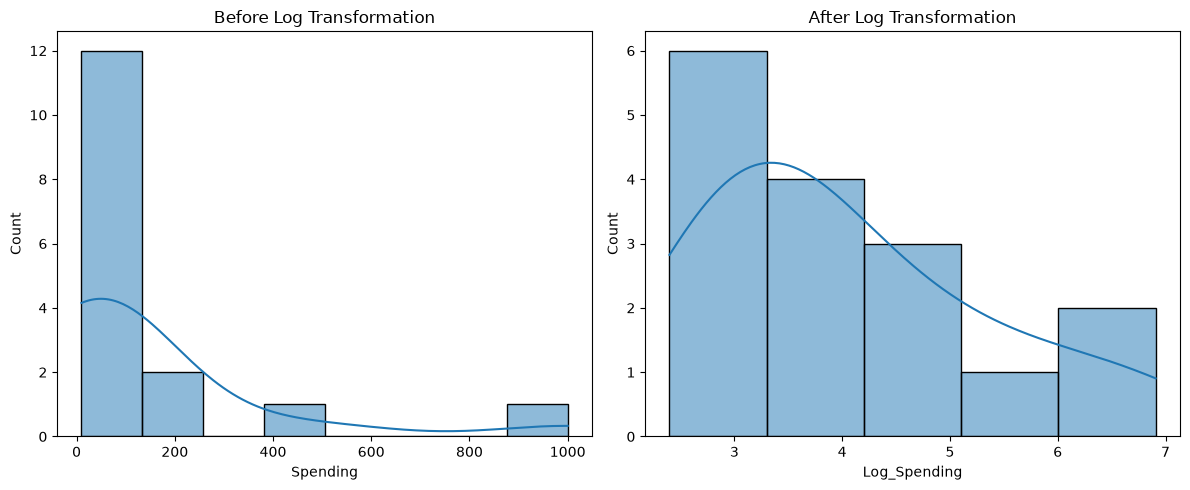

In [2]:
df["Log_Spending"] = np.log1p(df["Spending"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df["Spending"], kde=True, ax=axes[0])
axes[0].set_title("Before Log Transformation")

sns.histplot(df["Log_Spending"], kde=True, ax=axes[1])
axes[1].set_title("After Log Transformation")

plt.tight_layout()
plt.show()

## Result / Observation

The log transformation compressed the larger spending values.

The transformed distribution is less stretched toward the right compared with the original distribution.

Log transformation is useful when the feature is positive and strongly right-skewed.

It should not be blindly applied to every numerical feature.

# 3. Square Root Transformation


## Step 1 – Understand Concept

Square root transformation applies the square root function to numerical values.

It reduces the effect of large values but is generally less aggressive than log transformation.

It is often useful for moderately right-skewed data.

Square root transformation is commonly used for:

- Count data
- Event frequencies
- Moderately skewed numerical features

The standard square root transformation requires non-negative values.



## Step 2 – Demonstrate Concept

Consider:

4
16
100

Square root transformation gives:

4 → 2
16 → 4
100 → 10

The larger value is compressed.

Compared with logarithmic transformation, square root transformation generally produces a milder compression.



## Step 3 – Implement the Concept

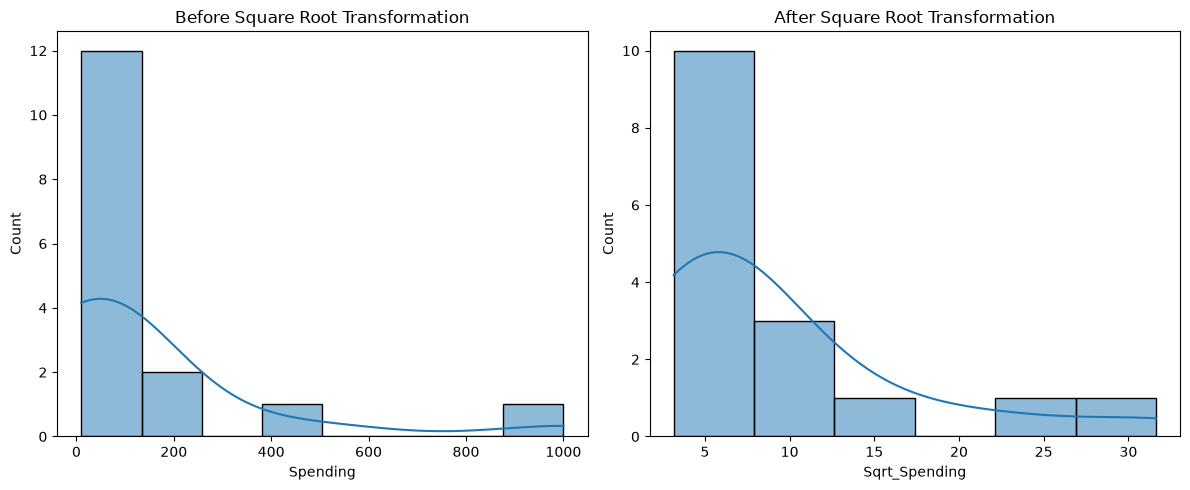

In [3]:
df["Sqrt_Spending"] = np.sqrt(df["Spending"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df["Spending"], kde=True, ax=axes[0])
axes[0].set_title("Before Square Root Transformation")

sns.histplot(df["Sqrt_Spending"], kde=True, ax=axes[1])
axes[1].set_title("After Square Root Transformation")

plt.tight_layout()
plt.show()

## Result / Observation

Square root transformation reduced the influence of large values.

It provides less compression than log transformation.

It can be considered when the feature has moderate positive skewness or count-like values.

# 4. Power Transformation


## Step 1 – Understand Concept

Power transformation applies a mathematical power transformation to change the shape of a distribution.

It can be used to reduce skewness and make numerical features more suitable for algorithms that work better with approximately symmetric data.

Instead of manually choosing only log or square root, power transformation methods can estimate a suitable transformation parameter from the data.

Two common power transformation methods are:

- Box-Cox
- Yeo-Johnson



## Step 2 – Demonstrate Concept

Suppose a numerical feature is strongly skewed.

Instead of manually deciding:

log(x)

or:

sqrt(x)

a power transformation can search for a suitable transformation parameter.

The objective is to make the distribution more symmetric while preserving the relative structure of the data as much as possible.




## Step 3 – Implement the Concept

In [4]:
from sklearn.preprocessing import PowerTransformer

power_transformer = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

df["Power_Transformed"] = power_transformer.fit_transform(
    df[["Spending"]]
)

print(df[[
    "Spending",
    "Power_Transformed"
]].head())

   Spending  Power_Transformed
0        10           1.618628
1        12           1.688301
2        15           1.769374
3        18           1.832127
4        20           1.866960


## Result / Observation

PowerTransformer automatically estimated a transformation parameter for the feature.

Yeo-Johnson was used here because it is more flexible about the input values than Box-Cox.

Power transformation can be useful when a manually selected log or square root transformation does not provide a satisfactory distribution.

# 5. Box-Cox Transformation



## Step 1 – Understand Concept

Box-Cox is a power transformation technique designed for strictly positive numerical data.

It estimates a parameter called lambda (λ) to find a suitable power transformation.

The goal is often to reduce skewness and make the distribution more symmetric.

Important requirement:

Box-Cox requires strictly positive values.

It cannot directly handle zero or negative values.



## Step 2 – Demonstrate Concept

Suppose:

Revenue =
10
20
50
100
500

All values are positive.

Box-Cox can search for an appropriate lambda value instead of requiring us to manually select log or square root.

If the data contains zero or negative values, Box-Cox cannot be directly applied without an appropriate preprocessing decision.




## Step 3 – Implement the Concept

In [5]:
from sklearn.preprocessing import PowerTransformer

boxcox = PowerTransformer(
    method="box-cox",
    standardize=False
)

df["BoxCox_Spending"] = boxcox.fit_transform(
    df[["Spending"]]
)

print("Estimated lambda:")
print(boxcox.lambdas_)

print("\nTransformed data:")
print(df[[
    "Spending",
    "BoxCox_Spending"
]].head())

Estimated lambda:
[-0.3299514]

Transformed data:
   Spending  BoxCox_Spending
0        10         1.613003
1        12         1.695776
2        15         1.790534
3        18         1.862942
4        20         1.902842


## Result / Observation

Box-Cox estimated a lambda value and transformed the positive feature accordingly.

Box-Cox can be useful for positive, skewed numerical features.

However, it should not be used directly when the feature contains zero or negative values.

# 6. Yeo-Johnson Transformation



## Step 1 – Understand Concept

Yeo-Johnson is another power transformation method.

Its major advantage is that it can handle:

- Positive values
- Zero
- Negative values

This makes it more flexible than Box-Cox.

Scikit-learn's PowerTransformer supports Yeo-Johnson by default.

It estimates a suitable lambda value from the data.



## Step 2 – Demonstrate Concept

Suppose a feature contains:

-100
-20
-5
0
10
30
100

Box-Cox cannot directly handle these values because they are not all strictly positive.

Yeo-Johnson can be considered because it supports zero and negative values.

This makes Yeo-Johnson useful for datasets containing mixed-sign numerical features.



## Step 3 – Implement the Concept

In [6]:
mixed_data = pd.DataFrame({
    "Value": [
        -100, -20, -5, 0,
        10, 30, 100
    ]
})

yeo_johnson = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

mixed_data["YeoJohnson"] = yeo_johnson.fit_transform(
    mixed_data[["Value"]]
)

print(mixed_data)
print("\nEstimated lambda:")
print(yeo_johnson.lambdas_)

   Value  YeoJohnson
0   -100  -97.351910
1    -20  -19.680549
2     -5   -4.958022
3      0    0.000000
4     10   10.120965
5     30   30.566625
6    100  102.724460

Estimated lambda:
[1.00733598]


## Result / Observation

Yeo-Johnson successfully transformed a feature containing negative, zero, and positive values.

Therefore:

Box-Cox → strictly positive data

Yeo-Johnson → positive, zero, and negative data

The choice depends on the values present in the feature.

# 7. Handling Skewed Data



## Step 1 – Understand Concept

Skewness describes how much a distribution is asymmetric.

Right-skewed distribution:
- Long tail toward larger values.
- Mean is often greater than median.

Left-skewed distribution:
- Long tail toward smaller values.
- Mean is often less than median.

A highly skewed feature can affect some statistical methods and ML algorithms.

Possible approaches include:

- Log transformation
- Square root transformation
- Power transformation
- Box-Cox
- Yeo-Johnson
- Keeping the original data when transformation is not necessary

Transformation should be based on the actual distribution and business meaning.



## Step 2 – Demonstrate Concept

Suppose MonthlyCharges has a long right tail.

We can inspect:

1. Histogram
2. KDE curve
3. Skewness value
4. Box plot

Then select a suitable transformation.

For example:

Strong right skew + positive values
→ Log / Box-Cox may be considered.

Moderate right skew
→ Square root may be considered.

Positive and negative values
→ Yeo-Johnson may be considered.



## Step 3 – Implement the Concept

In [7]:
original_skewness = df["Spending"].skew()
log_skewness = df["Log_Spending"].skew()
sqrt_skewness = df["Sqrt_Spending"].skew()

print("Original skewness:", original_skewness)
print("Log transformed skewness:", log_skewness)
print("Square root transformed skewness:", sqrt_skewness)

Original skewness: 2.8004303352327877
Log transformed skewness: 0.9019759366589476
Square root transformed skewness: 1.9520549866859256


## Result / Observation

Skewness values can help compare the distribution before and after transformation.

A transformation that reduces skewness may be useful, but the lowest skewness value should not be the only decision criterion.

The transformation should also preserve meaningful business information and be suitable for the chosen ML algorithm.

# 8. Normalization


## Step 1 – Understand Concept

Normalization changes the scale of numerical values, commonly into a bounded range such as 0 to 1.

It is different from distribution-shape transformations such as log or Box-Cox.

For example:

Original:
10, 20, 30, 40

Min-Max normalization:
0, 0.33, 0.67, 1

Normalization is useful when features need to be represented on a comparable bounded scale.

It does not necessarily make a skewed distribution symmetric.



## Step 2 – Demonstrate Concept

Suppose:

Age = 20 to 60
Income = 20,000 to 100,000

Min-Max normalization can map both features into a 0–1 range.

However, if Income is strongly skewed, normalization does not automatically remove that skewness.

It changes the scale rather than necessarily changing the distribution shape.




## Step 3 – Implement the Concept

In [8]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df["Normalized_Spending"] = scaler.fit_transform(
    df[["Spending"]]
)

print(df[[
    "Spending",
    "Normalized_Spending"
]].head())

   Spending  Normalized_Spending
0        10             0.000000
1        12             0.002020
2        15             0.005051
3        18             0.008081
4        20             0.010101


## Result / Observation

The feature was transformed into the 0–1 range.

Normalization changes the scale of the feature.

It should not be confused with transformations such as log, Box-Cox, or Yeo-Johnson, whose purpose can include changing the distribution shape.

# 9. Standardization


## Step 1 – Understand Concept

Standardization transforms a numerical feature so that it is centered around a mean of approximately 0 with a standard deviation of approximately 1.

It changes the scale but does not guarantee a normal distribution.

Standardization is commonly useful for algorithms that are sensitive to feature scale.

Examples:

- Logistic Regression
- Linear Regression
- SVM
- KNN
- PCA
- Neural Networks



## Step 2 – Demonstrate Concept

Suppose:

Age = 20 to 60

After standardization, values are represented according to their distance from the mean.

A value above the mean receives a positive standardized value.

A value below the mean receives a negative standardized value.

Standardization should therefore be understood as scaling, not as a guarantee that the data becomes normally distributed.



## Step 3 – Implement the Concept

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df["Standardized_Spending"] = scaler.fit_transform(
    df[["Spending"]]
)

print(df[[
    "Spending",
    "Standardized_Spending"
]].head())

   Spending  Standardized_Spending
0        10              -0.535893
1        12              -0.527973
2        15              -0.516091
3        18              -0.504210
4        20              -0.496289


## Result / Observation

The feature was centered and scaled according to its mean and standard deviation.

Standardization changes the scale of the data.

It does not automatically remove skewness or make the feature perfectly normally distributed.

# 10. Before and After Distribution Comparison


## Step 1 – Understand Concept

A transformation should be evaluated by comparing the distribution before and after transformation.

Useful comparisons include:

- Histogram
- KDE plot
- Box plot
- Skewness
- Mean
- Median
- Minimum and maximum
- Standard deviation

The goal is not simply to make a graph look normal.

We should check whether the transformation:

- Reduces unwanted skewness
- Compresses extreme values appropriately
- Preserves useful information
- Improves suitability for the intended ML algorithm



## Step 2 – Demonstrate Concept

Before transformation:

- Right-skewed distribution
- Long right tail
- Large values dominate the range

After log transformation:

- Large values are compressed
- Distribution may become less right-skewed
- Differences among smaller values become more visible

The transformation should be accepted only if it makes sense for the feature and the ML task.



## Step 3 – Implement the Concept

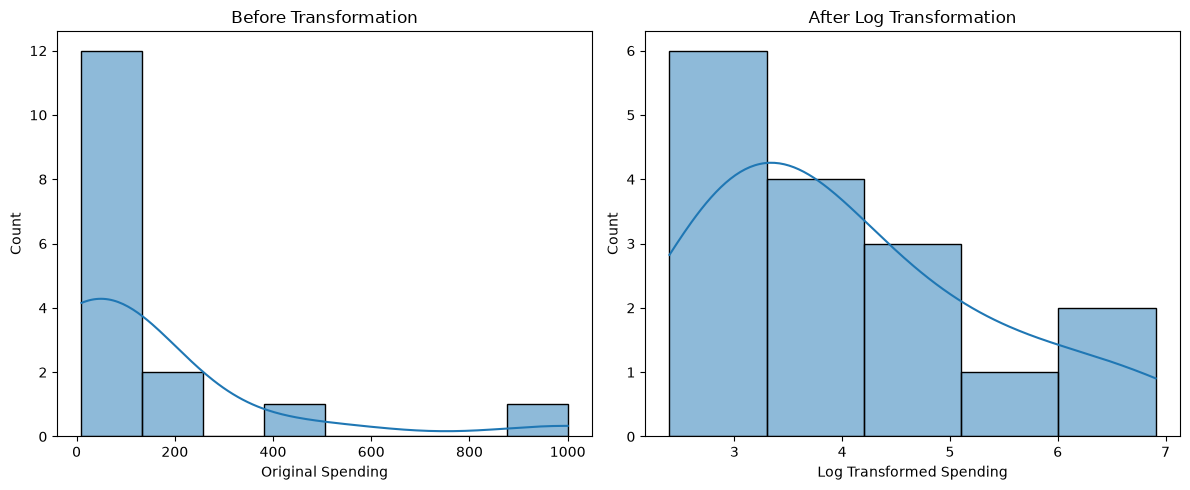

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    df["Spending"],
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Before Transformation")
axes[0].set_xlabel("Original Spending")

sns.histplot(
    df["Log_Spending"],
    kde=True,
    ax=axes[1]
)

axes[1].set_title("After Log Transformation")
axes[1].set_xlabel("Log Transformed Spending")

plt.tight_layout()
plt.show()

## Result / Observation

The two distributions can now be visually compared.

The transformed feature should be checked for:

- Reduced skewness
- Reduced influence of very large values
- Preservation of useful variation

Visual inspection should be combined with numerical measures such as skewness.

# 11. Comparing Multiple Transformations



## Step 1 – Understand Concept

Different transformations affect the same feature differently.

For a right-skewed positive feature, we can compare:

- Original
- Log
- Square Root
- Box-Cox
- Yeo-Johnson

The best transformation depends on the data.

We should not automatically select the transformation with the lowest skewness without considering the ML algorithm and business meaning.



## Step 2 – Demonstrate Concept

For our Spending feature:

Original
→ Strong right skew

Log
→ Strong compression of large values

Square Root
→ Moderate compression

Box-Cox
→ Data-driven power transformation for positive values

Yeo-Johnson
→ Flexible power transformation that can handle zero and negative values



## Step 3 – Implement the Concept

In [11]:
comparison = pd.DataFrame({
    "Original": df["Spending"],
    "Log": df["Log_Spending"],
    "Square_Root": df["Sqrt_Spending"],
    "Box_Cox": df["BoxCox_Spending"],
    "Yeo_Johnson": df["Power_Transformed"]
})

print("Skewness comparison:")

for column in comparison.columns:
    print(
        f"{column}: "
        f"{comparison[column].skew():.4f}"
    )

Skewness comparison:
Original: 2.8004
Log: 0.9020
Square_Root: 1.9521
Box_Cox: 0.1796
Yeo_Johnson: 0.1925


## Result / Observation

The skewness of different transformed versions can be compared.

A transformation that reduces skewness may be a better candidate, but the final decision should also consider:

- Input requirements
- Outliers
- Business interpretation
- Model requirements
- Data leakage prevention

# 12. Visual Comparison of All Transformations




## Step 1 – Understand Concept

Visual comparison helps us understand how different transformations change the distribution.

Histograms can show:

- Shape
- Spread
- Skewness
- Concentration of observations

KDE curves provide an approximate view of the distribution density.



## Step 2 – Demonstrate Concept

We can compare:

Original → Log → Square Root → Box-Cox → Yeo-Johnson

The purpose is to identify whether a transformation:

- Reduces the long tail
- Produces a more balanced distribution
- Compresses extreme values
- Preserves useful variation




## Step 3 – Implement the Concept

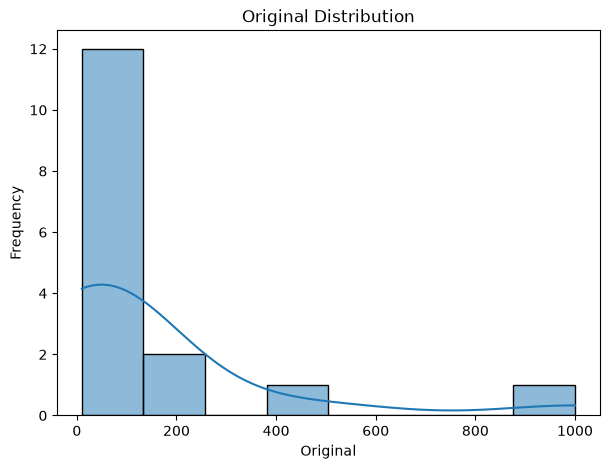

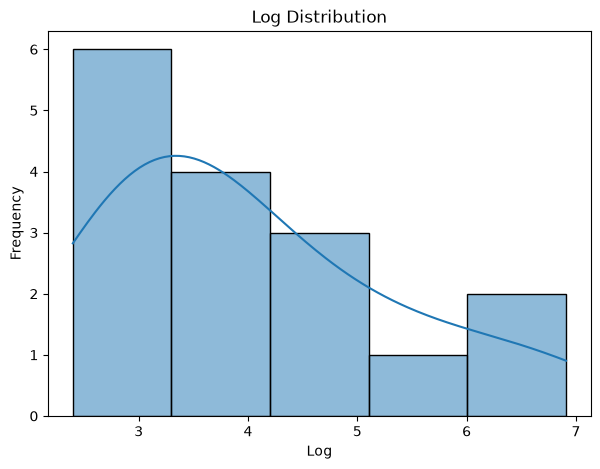

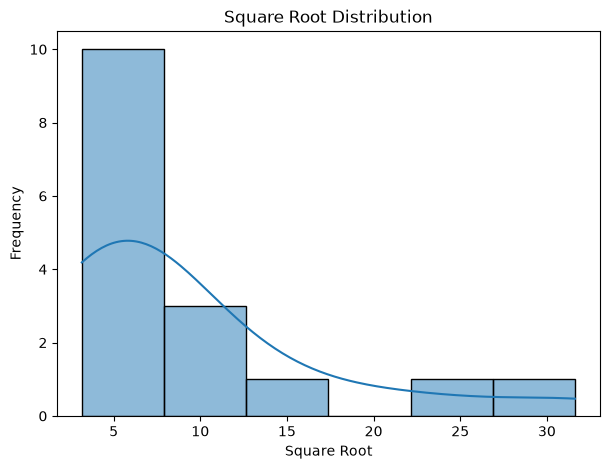

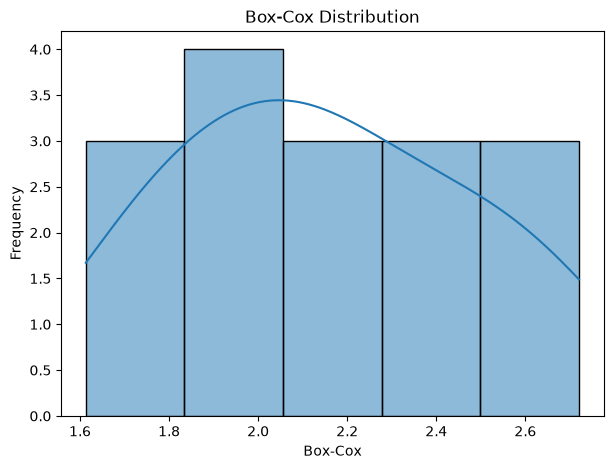

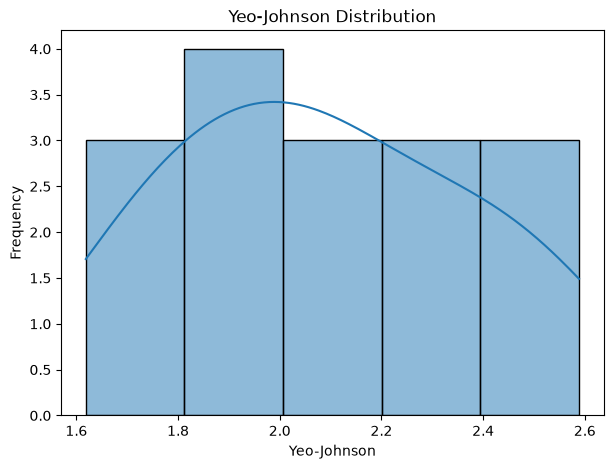

In [12]:
transformations = {
    "Original": df["Spending"],
    "Log": df["Log_Spending"],
    "Square Root": df["Sqrt_Spending"],
    "Box-Cox": df["BoxCox_Spending"],
    "Yeo-Johnson": df["Power_Transformed"]
}

for name, values in transformations.items():

    plt.figure(figsize=(7, 5))

    sns.histplot(
        values,
        kde=True
    )

    plt.title(f"{name} Distribution")
    plt.xlabel(name)
    plt.ylabel("Frequency")

    plt.show()

## Result / Observation

Each transformation changes the distribution differently.

The comparison should focus on whether the transformation improves the feature for its intended purpose.

A perfectly normal-looking distribution is not always required for Machine Learning.

# 13. Transformation Decision Guide


## Step 1 – Understand Concept

There is no single transformation that works for every feature.

The choice depends on:

- Skewness
- Presence of zero
- Presence of negative values
- Outliers
- Distribution shape
- Business meaning
- ML algorithm


## Step 2 – Demonstrate Concept

General decision guide:

Positive + strongly right-skewed
→ Log transformation may be considered.

Positive + moderately right-skewed
→ Square root may be considered.

Positive data + data-driven power transformation
→ Box-Cox may be considered.

Data containing zero or negative values
→ Yeo-Johnson may be considered.

Need a fixed numerical range
→ Normalization / Min-Max Scaling.

Need mean-centered features
→ Standardization.

Important:

Normalization and standardization are scaling techniques. They are not the same as transformations designed primarily to reduce skewness.



## Step 3 – Implement the Concept

In [13]:
decision_guide = pd.DataFrame({
    "Situation": [
        "Strong right skew + positive values",
        "Moderate right skew",
        "Positive data requiring power transformation",
        "Zero or negative values",
        "Need 0–1 range",
        "Need mean-centered features"
    ],
    "Possible_Approach": [
        "Log Transformation",
        "Square Root Transformation",
        "Box-Cox",
        "Yeo-Johnson",
        "Min-Max Normalization",
        "Standardization"
    ]
})

print(decision_guide)

                                      Situation           Possible_Approach
0           Strong right skew + positive values          Log Transformation
1                           Moderate right skew  Square Root Transformation
2  Positive data requiring power transformation                     Box-Cox
3                       Zero or negative values                 Yeo-Johnson
4                                Need 0–1 range       Min-Max Normalization
5                   Need mean-centered features             Standardization


## Result / Observation

The transformation should be selected based on the actual data characteristics.

The important process is:

Inspect → Understand → Transform → Compare → Validate → Select.

# 14. Complete Data Transformation Workflow



## Step 1 – Understand Concept

A proper transformation workflow should not blindly transform every numerical feature.

A practical workflow is:

1. Inspect the feature.
2. Check data type.
3. Check missing values.
4. Check outliers.
5. Measure skewness.
6. Plot the distribution.
7. Select a suitable transformation.
8. Fit the transformation using training data only.
9. Transform training data.
10. Apply the same fitted transformation to validation/test data.
11. Compare before and after.
12. Document the decision.



## Step 2 – Demonstrate Concept

Example:

Problem:
MonthlyCharges is strongly right-skewed.

Analysis:
The feature contains only positive values and has a long right tail.

Technique Selected:
Log transformation.

Reason:
Log transformation can compress large positive values and reduce right skewness.

Implementation:
Apply log transformation to the training data.

Result:
Compare skewness and distribution before and after.

Impact:
The transformed feature may be more suitable for a scale-sensitive ML model.



## Step 3 – Implement the Concept

In [14]:
# Example transformation workflow

feature = df[["Spending"]].copy()

print("Original skewness:")
print(feature["Spending"].skew())

# Apply log transformation
feature["Log_Spending"] = np.log1p(
    feature["Spending"]
)

print("\nTransformed skewness:")
print(feature["Log_Spending"].skew())

print("\nBefore and After:")
print(
    feature.head()
)

Original skewness:
2.8004303352327877

Transformed skewness:
0.9019759366589476

Before and After:
   Spending  Log_Spending
0        10      2.397895
1        12      2.564949
2        15      2.772589
3        18      2.944439
4        20      3.044522


## Result / Observation

Data transformation should be treated as a preprocessing decision rather than an automatic operation.

For every transformation, document:

- Problem
- Analysis
- Technique Selected
- Reason
- Implementation
- Result
- Impact

This makes the preprocessing decision easier to explain during an ML review.

# Final Summary – Data Transformation

In this notebook, we learned:

1. Why Transform Data?
2. Log Transformation
3. Square Root Transformation
4. Power Transformation
5. Box-Cox Transformation
6. Yeo-Johnson Transformation
7. Handling Skewed Data
8. Normalization
9. Standardization
10. Before and After Distribution Comparison
11. Comparing Multiple Transformations
12. Transformation Decision Guide
13. Complete Data Transformation Workflow

## Key Concepts

### Log Transformation
Useful for strongly right-skewed positive data.

### Square Root Transformation
Useful for moderate right skew and count-like data.

### Power Transformation
Can automatically estimate a suitable transformation parameter.

### Box-Cox
Requires strictly positive values.

### Yeo-Johnson
Can handle positive, zero, and negative values.

### Normalization
Changes the scale, commonly to 0–1.

### Standardization
Centers around 0 and scales according to standard deviation.

## Important Difference

Transformation methods such as:

- Log
- Square Root
- Box-Cox
- Yeo-Johnson

can change the shape of the distribution.

Scaling methods such as:

- Min-Max
- Standardization

mainly change the numerical scale.

## Before vs After

Always compare:

- Histogram
- KDE
- Box plot
- Skewness
- Mean
- Median
- Range
- Standard deviation

The objective is not necessarily to make every feature perfectly normal.

The objective is to create a representation that is appropriate for the data and the ML algorithm.